In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (1).zip to archive (1).zip


In [3]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/movie_dataset')

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [4]:
os.listdir('/content/movie_dataset')

['IMDb Movies India.csv']

In [6]:
df = pd.read_csv(
    '/content/movie_dataset/IMDb Movies India.csv',
    encoding='latin-1'
)

df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [7]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

df.info()

Shape: (15509, 10)

Columns:
Index(['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director',
       'Actor 1', 'Actor 2', 'Actor 3'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 15509
Columns: 10


In [10]:
print(df.columns.tolist())

['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']


In [11]:
df.isnull().sum()

,0
Name,0
Year,528
Duration,8269
Genre,1877
Rating,7590
Votes,7589
Director,525
Actor 1,1617
Actor 2,2384
Actor 3,3144


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 6


In [13]:
df.describe()

,Rating
count,7919.000000
mean,5.841621
std,1.381777
min,1.100000
25%,4.900000
50%,6.000000
75%,6.800000
max,10.000000


In [14]:
missing = (df.isnull().sum() / len(df)) * 100

print(missing.sort_values(ascending=False))

Duration    53.317429
Rating      48.939326
Votes       48.932878
Actor 3     20.272100
Actor 2     15.371720
Genre       12.102650
Actor 1     10.426204
Year         3.404475
Director     3.385131
Name         0.000000
dtype: float64


In [15]:
df.drop_duplicates(inplace=True)

In [16]:
print(df['Rating'].describe())

count    7919.000000
mean        5.841621
std         1.381777
min         1.100000
25%         4.900000
50%         6.000000
75%         6.800000
max        10.000000
Name: Rating, dtype: float64


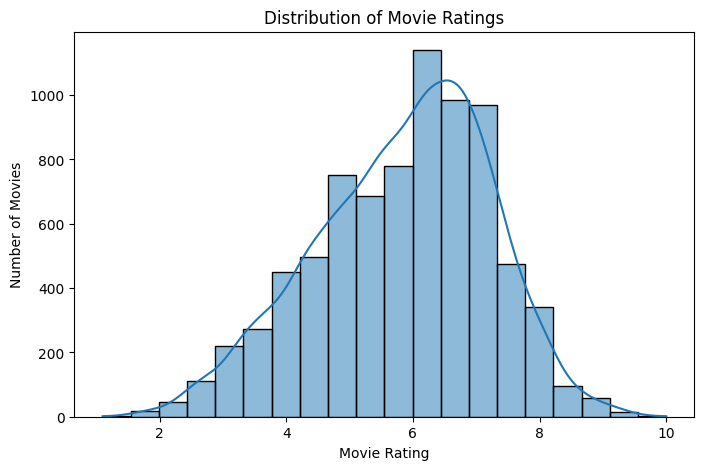

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['Rating'], bins=20, kde=True)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")

plt.show()

In [18]:
print(df.columns.tolist())

['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']


In [19]:
df = df[['Genre', 'Director', 'Actor 1',
         'Actor 2', 'Actor 3', 'Rating',
         'Year', 'Duration']]

In [21]:
print(df.isnull().sum())

Genre          0
Director       0
Actor 1        0
Actor 2        0
Actor 3        0
Rating         0
Year           0
Duration    2068
dtype: int64


In [22]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7919, 8)


In [23]:
df.head()

,Genre,Director,Actor 1,Actor 2,Actor 3,Rating,Year,Duration
1,Drama,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid,7.0,(2019),109 min
3,"Comedy, Romance",Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor,4.4,(2019),110 min
5,"Comedy, Drama, Musical",Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor,4.7,(1997),147 min
6,"Drama, Romance, War",Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma,7.4,(2005),142 min
8,"Horror, Mystery, Thriller",Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia,5.6,(2012),82 min


In [24]:
# Clean Year column
df['Year'] = df['Year'].astype(str).str.replace(
    r'[()]', '', regex=True
)

df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

# Clean Duration column
df['Duration'] = df['Duration'].astype(str).str.replace(
    ' min', '', regex=False
)

df['Duration'] = pd.to_numeric(
    df['Duration'], errors='coerce'
)

# Fill missing values
df['Year'] = df['Year'].fillna(df['Year'].median())
df['Duration'] = df['Duration'].fillna(df['Duration'].median())

print("Data conversion completed!")

Data conversion completed!


In [25]:
print(df.dtypes)

print("\nDataset:")
df.head()

Genre        object
Director     object
Actor 1      object
Actor 2      object
Actor 3      object
Rating      float64
Year          int64
Duration    float64
dtype: object

Dataset:


,Genre,Director,Actor 1,Actor 2,Actor 3,Rating,Year,Duration
1,Drama,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid,7.0,2019,109.0
3,"Comedy, Romance",Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor,4.4,2019,110.0
5,"Comedy, Drama, Musical",Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor,4.7,1997,147.0
6,"Drama, Romance, War",Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma,7.4,2005,142.0
8,"Horror, Mystery, Thriller",Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia,5.6,2012,82.0


In [26]:
print(df.isnull().sum())

Genre       0
Director    0
Actor 1     0
Actor 2     0
Actor 3     0
Rating      0
Year        0
Duration    0
dtype: int64


In [27]:
X = df.drop('Rating', axis=1)
y = df['Rating']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (7919, 7)
Target Shape: (7919,)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (6335, 7)
Testing Data: (1584, 7)


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    'Genre', 'Director',
    'Actor 1', 'Actor 2', 'Actor 3'
]

numerical_features = ['Year', 'Duration']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            max_categories=30
        ), categorical_features),

        ('num', 'passthrough', numerical_features)
    ]
)

print("Feature encoding setup completed!")

Feature encoding setup completed!


In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest Model Created!")

Random Forest Model Created!


In [ ]:
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

In [31]:
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [32]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 1.0424824705369686
MSE: 1.7976438915402508
RMSE: 1.3407624291947664
R2 Score: 0.03308039149704589


In [33]:
results = pd.DataFrame({
    'Actual Rating': y_test.values,
    'Predicted Rating': y_pred
})

print(results.head(10))

   Actual Rating  Predicted Rating
0            3.3          5.002833
1            5.3          4.940000
2            5.7          5.807600
3            7.2          5.017500
4            3.5          4.569000
5            7.2          5.694217
6            3.8          5.219500
7            6.9          4.659000
8            5.2          5.465017
9            7.4          4.798000


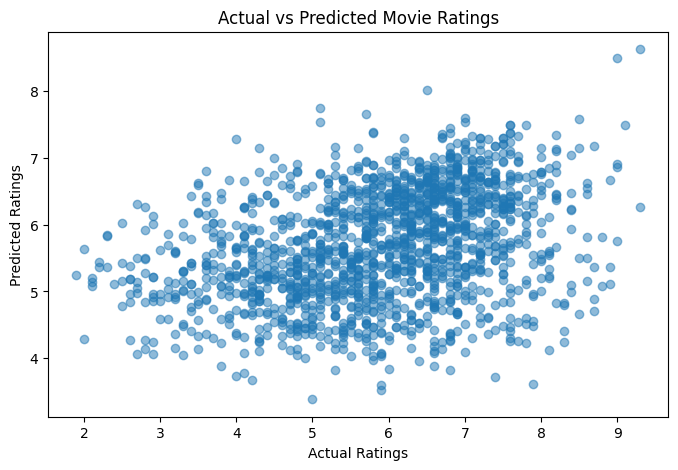

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.title("Actual vs Predicted Movie Ratings")

plt.show()

In [35]:
rf = model.named_steps['regressor']

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(15))

                              Feature  Importance
150                         num__Year    0.302809
151                     num__Duration    0.255986
29      cat__Genre_infrequent_sklearn    0.025582
19                   cat__Genre_Drama    0.021830
18             cat__Genre_Documentary    0.018207
89    cat__Actor 1_infrequent_sklearn    0.015359
59   cat__Director_infrequent_sklearn    0.014118
0                   cat__Genre_Action    0.013810
22          cat__Genre_Drama, Romance    0.011933
149   cat__Actor 3_infrequent_sklearn    0.011336
24                  cat__Genre_Horror    0.011191
4     cat__Genre_Action, Crime, Drama    0.011156
119   cat__Actor 2_infrequent_sklearn    0.010359
9                   cat__Genre_Comedy    0.008626
11           cat__Genre_Comedy, Drama    0.008552


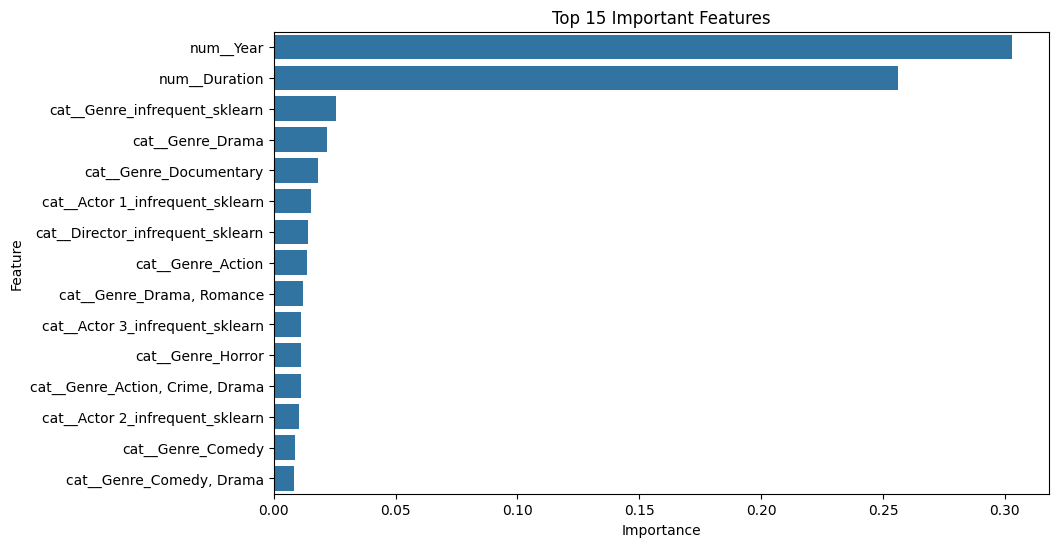

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

In [37]:
new_movie = pd.DataFrame({
    'Genre': ['Drama'],
    'Director': ['Unknown'],
    'Actor 1': ['Unknown'],
    'Actor 2': ['Unknown'],
    'Actor 3': ['Unknown'],
    'Year': [2024],
    'Duration': [120]
})

predicted_rating = model.predict(new_movie)

print("Predicted Movie Rating:",
      round(predicted_rating[0], 2))

Predicted Movie Rating: 6.16


In [38]:
import joblib

joblib.dump(model, 'movie_rating_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [39]:
from google.colab import files

files.download('movie_rating_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>